# Calidad: transforms para fotos de todos los tamaños

En `00-acceso/01_un_dataset_propio` armamos un `Dataset` que entrega cada foto de Oxford Flowers 102 con su etiqueta. El paso siguiente parece trivial: pasárselo a un `DataLoader` y pedir un lote. Falla. Las fotos tienen tamaños distintos y además llegan como imágenes PIL, no como tensores. En el video *Transform Pipelines* del curso este es el segundo de los tres problemas de un pipeline de datos, el de **calidad**: dejar cada imagen con el tamaño, el tipo y la escala que el modelo necesita.

En MNIST (`00-datos/01_transforms_dataset_y_dataloader` del módulo 2) todas las imágenes medían 28 × 28 y bastaba con `ToTensor` y `Normalize`. Con fotos reales hace falta más, y cada paso tiene detalles que conviene ver con los números:

- por qué falla el primer lote, con los dos mensajes de error que aparecen en el camino;
- `Resize` con un número o con dos, cuánto deforma cada opción y cuánto de la foto descarta `CenterCrop`;
- las tres cosas que hace `ToTensor`, comprobadas a mano;
- por qué escalar, medido en una capa recién creada;
- la media y la desviación de ImageNet (de dónde salen, y por qué su desviación no es la que uno calcularía) contra las de las flores;
- qué le hace `Normalize` a la distribución de los píxeles, y qué no;
- qué transformaciones aceptan imágenes PIL, cuáles tensores, y la API nueva, `transforms.v2`;
- cómo depurar un pipeline aplicando un paso a la vez.

El notebook tarda uno o dos minutos en una CPU.

**Contenido**

1. Preparación
2. Un `Dataset` mínimo
3. Fotos de todos los tamaños
4. El primer lote falla
5. El mismo tamaño para todas: `Resize` y `CenterCrop`
6. `ToTensor`: tres cambios en uno
7. Por qué escalar
8. `Normalize`: ¿la media de quién?
9. Qué le hace `Normalize` a los píxeles
10. El puente: PIL de un lado, tensores del otro
11. `transforms.v2`
12. Depurar paso a paso
13. El pipeline completo
14. Resumen y ejercicios

## 1. Preparación

Los datos son los de todo el módulo, en `modulo-3/data`. `datasets.Flowers102` los descarga la primera vez (unos 345 MB). Aquí lo usamos solo para eso y para leer los nombres de las clases: el `Dataset` lo escribimos nosotros.

In [1]:
import os
import warnings
from collections import Counter

import numpy as np
import scipy.io
import torch
from torch import nn
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

torch.manual_seed(0)
print("Versión de PyTorch    :", torch.__version__)
print("Versión de torchvision:", torchvision.__version__)

RAIZ = "../data"                                     # modulo-3/data
nombres = datasets.Flowers102(root=RAIZ, download=True).classes
CARPETA = os.path.join(RAIZ, "flowers-102")
print("clases:", len(nombres), "  las tres primeras:", nombres[:3])

Versión de PyTorch    : 2.11.0+cpu
Versión de torchvision: 0.26.0+cpu
clases: 102   las tres primeras: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells']


## 2. Un `Dataset` mínimo

La versión corta del `Dataset` de `00-acceso/01_un_dataset_propio`, donde se explica cada decisión. Lo esencial:

- `__init__` lee solo las etiquetas del archivo `.mat` y les resta 1, porque vienen de 1 a 102 y PyTorch espera clases de 0 a 101.
- `__getitem__(i)` abre el archivo `image_{i + 1:05d}.jpg`, porque los nombres empiezan en `00001`.
- `Image.open` es perezoso: según la documentación de Pillow, identifica el archivo pero no lee los píxeles hasta que se usan ([`PIL.Image.open`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open)). `convert("RGB")` devuelve una copia ya leída ([`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert)), y el `with` cierra el archivo al salir.

In [2]:
class Flores(Dataset):
    """Oxford Flowers 102 leído desde los archivos crudos."""

    def __init__(self, carpeta, transform=None):
        self.carpeta = carpeta
        etiquetas = scipy.io.loadmat(os.path.join(carpeta, "imagelabels.mat"))["labels"][0]
        self.etiquetas = etiquetas - 1                  # de 1-102 a 0-101
        self.transform = transform

    def __len__(self):
        return len(self.etiquetas)

    def ruta(self, i):
        return os.path.join(self.carpeta, "jpg", f"image_{i + 1:05d}.jpg")    # los archivos parten en 00001

    def __getitem__(self, i):
        with Image.open(self.ruta(i)) as archivo:
            imagen = archivo.convert("RGB")             # lee los píxeles; el with cierra el archivo
        if self.transform:
            imagen = self.transform(imagen)
        return imagen, int(self.etiquetas[i])


flores = Flores(CARPETA)
imagen, etiqueta = flores[0]
print(len(flores), "fotos")
print("flores[0]:", type(imagen).__name__, " tamaño", imagen.size, " modo", imagen.mode,
      "  etiqueta", etiqueta, f"({nombres[etiqueta]})")

8189 fotos
flores[0]: Image  tamaño (591, 500)  modo RGB   etiqueta 76 (passion flower)


Sin transformación, cada muestra es una imagen PIL. Su atributo `.size` es `(ancho, alto)` ([`Image.size`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.size)): esta foto mide 591 píxeles de ancho y 500 de alto. Ojo con ese orden, porque los tensores de imágenes de PyTorch usan el contrario, `[canales, alto, ancho]`.

## 3. Fotos de todos los tamaños

`00-acceso/01_un_dataset_propio` ya describió los tamaños: 856 distintos, casi todos con el lado corto de 500 píxeles y la mayoría horizontales. Los volvemos a leer del encabezado de cada archivo (sin decodificar las fotos, así que es rápido) porque las secciones siguientes los usan, y miramos dos cosas nuevas: el modo de color y la proporción entre ancho y alto, que es lo que decide cuánto deforma o recorta cada transformación.

In [3]:
tamanos, modos = [], Counter()
for i in range(len(flores)):
    with Image.open(flores.ruta(i)) as archivo:         # solo lee el encabezado
        tamanos.append(archivo.size)                     # (ancho, alto)
        modos[archivo.mode] += 1

anchos = np.array([ancho for ancho, _ in tamanos])
altos = np.array([alto for _, alto in tamanos])
proporcion = anchos / altos                              # ancho / alto
lado_corto = np.minimum(anchos, altos)

print("modos de color:", dict(modos))
print("tamaños distintos:", len(set(tamanos)))
print(f"proporción ancho/alto: mínima {proporcion.min():.3f}, mediana {np.median(proporcion):.3f}, máxima {proporcion.max():.3f}")
for nombre, valor in [("4:3", 4 / 3), ("3:2", 3 / 2), ("3:4", 3 / 4)]:
    print(f"   cerca de {nombre} (a menos de 1%): {(np.abs(proporcion / valor - 1) < 0.01).mean():.0%} de las fotos")

modos de color: {'RGB': 8189}
tamaños distintos: 856
proporción ancho/alto: mínima 0.428, mediana 1.332, máxima 2.048
   cerca de 4:3 (a menos de 1%): 27% de las fotos
   cerca de 3:2 (a menos de 1%): 17% de las fotos
   cerca de 3:4 (a menos de 1%): 4% de las fotos


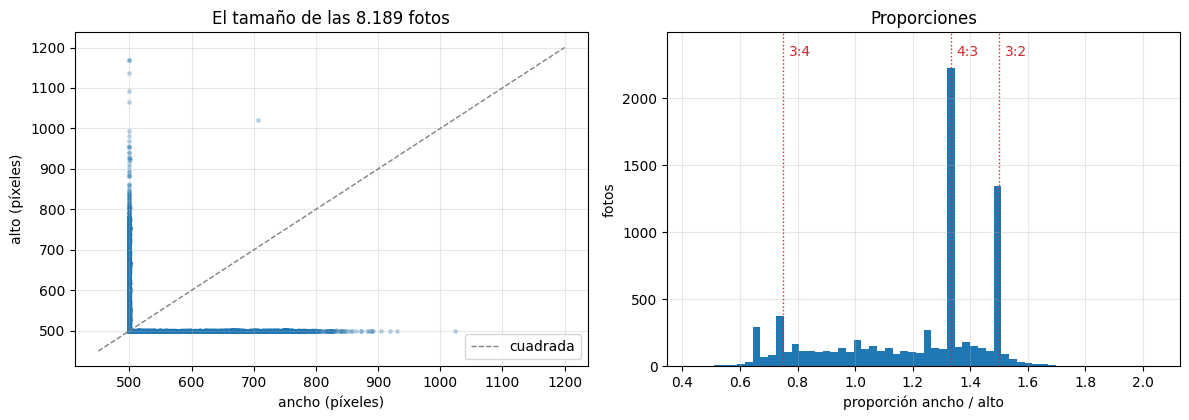

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3))

ejes[0].scatter(anchos, altos, s=6, alpha=0.25)
ejes[0].plot([450, 1200], [450, 1200], color="gray", linestyle="--", linewidth=1, label="cuadrada")
ejes[0].set_xlabel("ancho (píxeles)")
ejes[0].set_ylabel("alto (píxeles)")
ejes[0].set_title("El tamaño de las 8.189 fotos")
ejes[0].legend()

conteos, _, _ = ejes[1].hist(proporcion, bins=60)
ejes[1].set_ylim(0, conteos.max() * 1.12)
for valor, texto in [(4 / 3, "4:3"), (3 / 2, "3:2"), (3 / 4, "3:4")]:
    ejes[1].axvline(valor, color="tab:red", linestyle=":", linewidth=1)
    ejes[1].text(valor + 0.02, conteos.max() * 1.04, texto, color="tab:red", ha="left")
ejes[1].set_xlabel("proporción ancho / alto")
ejes[1].set_ylabel("fotos")
ejes[1].set_title("Proporciones")

for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Las 8.189 fotos están en RGB, así que todas tienen tres canales y no hay que convertir ninguna de escala de grises. En el gráfico de la izquierda se ve el patrón del lado corto de 500: los puntos forman una L. A la derecha, las proporciones más comunes son 4:3 y 3:2, las de las cámaras de fotos: el 27% de las fotos está a menos de 1% de 4:3, y el 17% a menos de 1% de 3:2. El resto se reparte en un rango amplio. Los extremos son una foto el doble de ancha que de alta y otra más de dos veces más alta que ancha. La página del dataset avisa que las imágenes tienen "large scale, pose and light variations" ([VGG, *Overview*](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/)), y el tamaño es solo la primera de ellas.

## 4. El primer lote falla

Le pedimos al `DataLoader` un lote de cuatro fotos tal como salen del `Dataset`:

In [5]:
try:
    next(iter(DataLoader(flores, batch_size=4)))
except TypeError as error:
    print("TypeError:", error)

TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'PIL.Image.Image'>


Para armar un lote, el `DataLoader` pide las muestras una por una y se las pasa en una lista a su función `collate_fn`, que por defecto es `default_collate` ([*Working with collate_fn*](https://docs.pytorch.org/docs/stable/data.html#working-with-collate-fn)). Esa función sabe juntar tensores, arreglos de NumPy, números, textos, diccionarios y listas, y la documentación da la lista completa ([`default_collate`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.default_collate)). Una imagen PIL no está en la lista.

Con `ToTensor` cada foto se vuelve un tensor. Probamos de nuevo:

In [6]:
flores_tensor = Flores(CARPETA, transform=transforms.ToTensor())
for i in range(4):
    print(f"flores_tensor[{i}]:", tuple(flores_tensor[i][0].shape))

try:
    next(iter(DataLoader(flores_tensor, batch_size=4)))
except RuntimeError as error:
    print("\nRuntimeError:", error)

flores_tensor[0]: (3, 500, 591)
flores_tensor[1]: (3, 500, 625)
flores_tensor[2]: (3, 667, 500)
flores_tensor[3]: (3, 500, 667)



RuntimeError:

 stack expects each tensor to be equal size, but got [3, 500, 591] at entry 0 and [3, 500, 625] at entry 1


El error cambió. Ahora `default_collate` sí reconoce los tensores, y hace lo que dice su documentación: "It always prepends a new dimension as the batch dimension". Eso lo hace con `torch.stack`, que pone los tensores uno encima de otro, y para eso todos tienen que tener la misma forma. El lote es un solo tensor `[lote, canales, alto, ancho]`, y no existe un tensor donde una imagen mida 500 × 591 y la siguiente 500 × 625.

El mensaje dice exactamente qué pasó: la entrada 0 mide `[3, 500, 591]` y la entrada 1 `[3, 500, 625]`. Hay dos formas de salir de aquí: llevar todas las fotos al mismo tamaño, que es lo que se hace casi siempre, o escribir un `collate_fn` propio que arme el lote de otra manera (ejercicio 3). La documentación menciona `collate_fn` propios, por ejemplo para rellenar (*padding*) secuencias de largo variable.

## 5. El mismo tamaño para todas: `Resize` y `CenterCrop`

`transforms.Resize` acepta el tamaño de dos formas, y la diferencia importa. Según su documentación ([`Resize`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Resize.html)): "If size is a sequence like (h, w), output size will be matched to this. If size is an int, smaller edge of the image will be matched to this number."

- `Resize((224, 224))` lleva cualquier foto a 224 × 224, sin importar su proporción.
- `Resize(256)` lleva el lado corto a 256 y escala el largo en la misma proporción. Después, `CenterCrop(224)` recorta un cuadrado de 224 × 224 del centro ([`CenterCrop`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.CenterCrop.html)).

Con la primera foto:

In [7]:
deformar = transforms.Resize((224, 224))
achicar = transforms.Resize(256)
recortar = transforms.CenterCrop(224)

imagen, _ = flores[0]
deformada = deformar(imagen)
achicada = achicar(imagen)
recortada = recortar(achicada)

for nombre, foto in [("original", imagen), ("Resize((224, 224))", deformada),
                     ("Resize(256)", achicada), ("Resize(256) + CenterCrop", recortada)]:
    ancho, alto = foto.size
    print(f"{nombre:26s} {ancho:3d} × {alto:3d}   proporción {ancho / alto:.3f}")

original                   591 × 500   proporción 1.182
Resize((224, 224))         224 × 224   proporción 1.000
Resize(256)                302 × 256   proporción 1.180
Resize(256) + CenterCrop   224 × 224   proporción 1.000


`Resize(256)` dejó la foto en 302 × 256: el lado corto pasó de 500 a 256 y el largo se escaló igual, de 591 a 302 (el resultado se trunca a un entero). La proporción casi no cambió, 1.180 contra 1.182. `Resize((224, 224))`, en cambio, la dejó cuadrada: la apretó más en el ancho que en el alto.

¿Cuánto deforma `Resize((224, 224))` en todo el dataset? Una foto de proporción $r$ queda cuadrada, así que su lado largo se comprime $\max(r, 1/r)$ veces más que el corto. Y ¿cuánto descarta `CenterCrop`? Después de `Resize(256)` la foto mide $256 \times L$, con $L$ el lado largo escalado, y el recorte se queda con $224 \times 224$ de eso. Lo calculamos para las 8.189 fotos con los tamaños de la sección 3:

In [8]:
largo = np.maximum(anchos, altos)
compresion = np.maximum(proporcion, 1 / proporcion)       # cuánto más se comprime el lado largo

largo_256 = (256 * largo / lado_corto).astype(int)        # el lado largo después de Resize(256), truncado
conservado = 224 * 224 / (256 * largo_256)                # fracción del área que deja CenterCrop(224)
assert largo_256[0] == 302                                # coincide con la foto de arriba

print("Resize((224, 224)): el lado largo se comprime más que el corto en un factor de")
print(f"   mediana {np.median(compresion):.2f}   máximo {compresion.max():.2f}   "
      f"fotos con factor sobre 1.3: {(compresion > 1.3).mean():.0%}")
print("Resize(256) + CenterCrop(224): fracción de la foto que se conserva")
print(f"   mediana {np.median(conservado):.0%}   mínima {conservado.min():.0%}   máxima {conservado.max():.0%}")

Resize((224, 224)): el lado largo se comprime más que el corto en un factor de
   mediana 1.33   máximo 2.34   fotos con factor sobre 1.3: 68%
Resize(256) + CenterCrop(224): fracción de la foto que se conserva
   mediana 57%   mínima 33%   máxima 77%


Las dos opciones tienen un costo:

- `Resize((224, 224))` conserva toda la foto pero cambia las formas. En la mitad de las fotos el lado largo queda comprimido 1.33 veces más que el corto o peor, y en la más alargada, 2.34 veces: un pétalo redondo queda ovalado.
- `Resize(256)` + `CenterCrop(224)` conserva las formas pero bota los bordes. En la foto mediana se queda con el 57% del área, y en la más alargada con un 33%. Si la flor no está centrada, puede quedar cortada.

En el video *Transform Pipelines* del curso se elige la segunda, y es también la que usan muchos modelos de torchvision entrenados con ImageNet. La documentación de ResNet-50, en sus pesos `IMAGENET1K_V1`, dice que sus imágenes "are resized to resize_size=[256] using interpolation=InterpolationMode.BILINEAR, followed by a central crop of crop_size=[224]" ([`ResNet50_Weights`](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html#torchvision.models.ResNet50_Weights)). De ahí vienen el 256 y el 224. En fotos de flores es una elección razonable si, como parece en las que miramos, la flor suele estar al centro; no lo medimos en todo el dataset.

Las dos fotos más extremas, con el rectángulo que conserva `CenterCrop` marcado en el original:

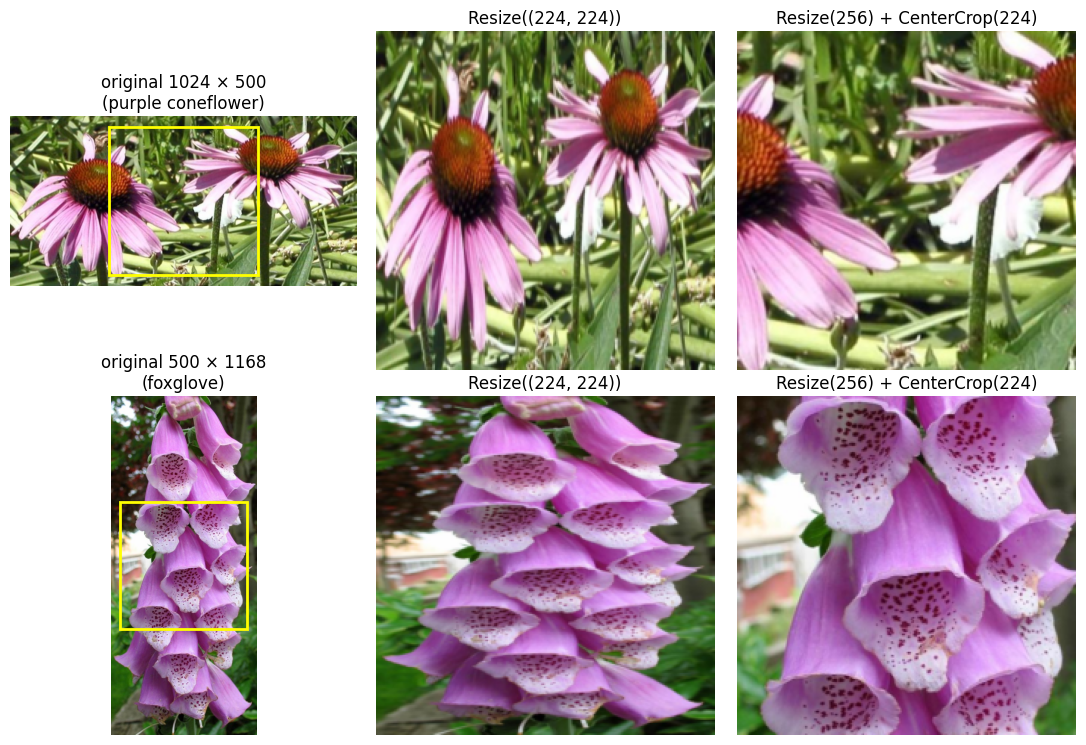

In [9]:
def recuadro_del_recorte(foto, lado=256, recorte=224):
    """El cuadrado que conserva Resize(lado) + CenterCrop(recorte), en coordenadas de la foto original."""
    ancho, alto = foto.size
    escala = min(ancho, alto) / lado              # cuántos píxeles originales hay por píxel achicado
    medida = recorte * escala
    return (ancho - medida) / 2, (alto - medida) / 2, medida


extremos = [int(proporcion.argmax()), int(proporcion.argmin())]
fig, ejes = plt.subplots(2, 3, figsize=(11, 7.5))
for fila, indice in enumerate(extremos):
    foto, etiqueta = flores[indice]
    x0, y0, medida = recuadro_del_recorte(foto)
    ejes[fila, 0].imshow(foto)
    ejes[fila, 0].add_patch(patches.Rectangle((x0, y0), medida, medida, fill=False, edgecolor="yellow", linewidth=2))
    ejes[fila, 0].set_title(f"original {foto.size[0]} × {foto.size[1]}\n({nombres[etiqueta]})")
    ejes[fila, 1].imshow(deformar(foto))
    ejes[fila, 1].set_title("Resize((224, 224))")
    ejes[fila, 2].imshow(recortar(achicar(foto)))
    ejes[fila, 2].set_title("Resize(256) + CenterCrop(224)")
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

En la foto ancha, `Resize((224, 224))` dejó las flores flacas y altas; en la alta, anchas y bajas. El recorte del centro mantiene las formas, y el precio se ve en el recuadro amarillo: en estas dos fotos queda fuera más de la mitad.

## 6. `ToTensor`: tres cambios en uno

La documentación de `ToTensor` lo resume en una frase: convierte "a PIL Image or numpy.ndarray (H x W x C) in the range [0, 255] to a torch.FloatTensor of shape (C x H x W) in the range [0.0, 1.0]" ([`ToTensor`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html)). Son tres cambios: el tipo, el orden de las dimensiones y la escala. Los hacemos a mano, uno a la vez, y comparamos:

In [10]:
arreglo = np.array(imagen)
print("NumPy               :", arreglo.shape, arreglo.dtype, f"valores de {arreglo.min()} a {arreglo.max()}")

a_mano = torch.from_numpy(arreglo)                  # 1. a tensor (sigue siendo uint8)
print("1. tensor           :", tuple(a_mano.shape), a_mano.dtype)
a_mano = a_mano.permute(2, 0, 1)                    # 2. de [alto, ancho, canales] a [canales, alto, ancho]
print("2. canales primero  :", tuple(a_mano.shape), a_mano.dtype)
a_mano = a_mano.float() / 255                       # 3. a float32, entre 0 y 1
print("3. dividir por 255  :", tuple(a_mano.shape), a_mano.dtype, f"valores de {a_mano.min():.1f} a {a_mano.max():.1f}")

con_totensor = transforms.ToTensor()(imagen)
print("\nToTensor            :", tuple(con_totensor.shape), con_totensor.dtype)
print("¿Idénticos?", torch.equal(a_mano, con_totensor))

NumPy               : (500, 591, 3) uint8 valores de 0 a 255
1. tensor           : (500, 591, 3) torch.uint8
2. canales primero  : (3, 500, 591) torch.uint8
3. dividir por 255  : (3, 500, 591) torch.float32 valores de 0.0 a 1.0

ToTensor            : (3, 500, 591) torch.float32
¿Idénticos? True


Idénticos, bit a bit. El paso 2 es el que más confunde: PIL y NumPy guardan las imágenes como `[alto, ancho, canales]` (el color de cada píxel va junto), y PyTorch las quiere como `[canales, alto, ancho]` (tres planos, uno por color). `permute` no copia nada, solo cambia el orden en que se recorren los datos (`00-fundamentos/02_tensores_a_fondo` del módulo 1, sección 4).

La división por 255 tiene una condición: según la documentación, solo se hace si la imagen PIL está en uno de los modos habituales (RGB, L y otros) o si el arreglo de NumPy es `uint8`. Un arreglo `float` o `int32` pasa sin dividir, y es un bug silencioso posible cuando las imágenes se arman a mano.

## 7. Por qué escalar

El curso da dos razones para llevar los píxeles de 0-255 a 0-1: que las características queden en la misma escala, y que los números grandes desestabilizan las multiplicaciones de la red. La segunda se puede medir. Tomamos 64 fotos y una capa lineal recién creada que va de los $3 \times 224 \times 224 = 150.528$ píxeles a las 102 clases, y le pasamos las mismas fotos en tres escalas:

In [11]:
sin_escalar = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.PILToTensor()])
elegidas = torch.randperm(len(flores), generator=torch.Generator().manual_seed(0))[:64].tolist()
X = torch.stack([sin_escalar(flores[i][0]) for i in elegidas]).float()      # valores de 0 a 255
y = torch.tensor([flores.etiquetas[i] for i in elegidas])

MEDIA_IMAGENET = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESV_IMAGENET = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

torch.manual_seed(0)
capa = nn.Linear(3 * 224 * 224, 102)
print(f"pérdida de adivinar al azar entre 102 clases: ln(102) = {np.log(102):.2f}\n")
for nombre, x in [("de 0 a 255", X), ("de 0 a 1", X / 255), ("normalizadas", (X / 255 - MEDIA_IMAGENET) / DESV_IMAGENET)]:
    logits = capa(x.flatten(1))
    perdida = nn.functional.cross_entropy(logits, y)
    capa.zero_grad()
    perdida.backward()
    confianza = logits.softmax(dim=1).max(dim=1).values.mean()
    print(f"{nombre:13s} desviación de los logits {logits.std():7.2f}   confianza media {confianza:5.1%}   "
          f"pérdida {perdida:7.2f}   norma del gradiente {capa.weight.grad.norm():9.1f}")

pérdida de adivinar al azar entre 102 clases: ln(102) = 4.62



de 0 a 255    desviación de los logits   74.30   confianza media 96.0%   pérdida  196.26   norma del gradiente   23266.2
de 0 a 1      desviación de los logits    0.29   confianza media  2.0%   pérdida    4.70   norma del gradiente      26.6
normalizadas  desviación de los logits    0.71   confianza media  4.6%   pérdida    4.83   norma del gradiente      63.9


Con los píxeles de 0 a 255, una capa que todavía no aprendió nada ya está segura de sus respuestas: en promedio le da 96% de probabilidad a una sola clase, que no tiene nada que ver con la foto. Como casi siempre es la equivocada, la pérdida inicial es 196, cuando adivinar parejo entre 102 clases da $\ln 102 \approx 4.62$. Y el gradiente es unas 875 veces más grande que con los píxeles entre 0 y 1: una tasa de aprendizaje razonable para una escala haría saltar los pesos en la otra.

Con los píxeles escalados, la capa empieza donde debe: confianza baja y pérdida cerca de 4.62. Es la misma idea que vimos con una sola variable en `02-descenso-de-gradiente/01_descenso_de_gradiente` del módulo 1, sección 8: la escala de las entradas decide la forma de la superficie de pérdida.

## 8. `Normalize`: ¿la media de quién?

`Normalize` resta una media y divide por una desviación en cada canal, con la fórmula de su documentación: `output[channel] = (input[channel] - mean[channel]) / std[channel]` ([`Normalize`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Normalize.html)). En MNIST calculamos esos dos números con el conjunto de entrenamiento (`00-datos/01_transforms_dataset_y_dataloader` del módulo 2, sección 5). En casi todos los ejemplos con fotos, en cambio, aparecen otros seis números: `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]`.

Son los que usan los modelos de torchvision entrenados con ImageNet. La documentación de ResNet-50 dice que sus imágenes se llevan a [0, 1] "and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]", y la guía de modelos insiste en que al usar un modelo preentrenado "Using the correct preprocessing method is critical and failing to do so may lead to decreased accuracy or incorrect outputs" ([*Using the pre-trained models*](https://docs.pytorch.org/vision/stable/models.html#using-the-pre-trained-models)).

¿De dónde salen? La documentación no lo dice. En 2019 alguien lo preguntó en el repositorio de torchvision ([issue #1439](https://github.com/pytorch/vision/issues/1439)) y las respuestas fueron reveladoras:

- Los mismos números aparecen en `fb.resnet.torch`, un script de Facebook para entrenar con ImageNet en Lua, junto a un comentario: "Computed from random subset of ImageNet training images". El autor del issue resume que el procedimiento se conoce a grandes rasgos, pero que "the concrete `subset` that was used is lost".
- Quien los llevó a PyTorch dice que probablemente los copió de "the previous Lua ImageNet training script", otro script en Lua (`imagenet-multiGPU.torch`), y que ese script calcula la desviación de una forma particular: "It uses the average standard deviation of an individual image's channel instead of the an estimate of the standard deviation across the entire dataset". Es decir, la desviación de ImageNet no es la de todos los píxeles juntos, sino el promedio de las desviaciones de cada imagen.

Calculemos las dos versiones para las flores. Primero, una regla del módulo 2: las estadísticas se calculan **solo con el conjunto de entrenamiento**. Usamos la misma división que se arma en `02-carga/01_division_y_dataloader`: `random_split` con la semilla 0, 70% para entrenar, 15% para validar y el resto para la prueba. Allí se explica en detalle; aquí solo necesitamos los índices de entrenamiento, y de ellos sacamos al azar una muestra de 1.000 fotos. Cada una pasa por `Resize(256)`, `CenterCrop(224)` y `ToTensor`, que es lo que verá el modelo. Para no guardar 600 MB de píxeles en memoria, vamos acumulando sumas:

In [12]:
n = len(flores)
n_entrenamiento, n_validacion = int(0.7 * n), int(0.15 * n)
division = random_split(flores, [n_entrenamiento, n_validacion, n - n_entrenamiento - n_validacion],
                        generator=torch.Generator().manual_seed(0))
print("entrenamiento, validación y prueba:", [len(parte) for parte in division])

entrenamiento = torch.tensor(division[0].indices)                            # los índices del 70% de entrenamiento
muestra = entrenamiento[torch.randperm(len(entrenamiento), generator=torch.Generator().manual_seed(1))[:1000]]

preparar = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor()])

suma = torch.zeros(3, dtype=torch.float64)
suma_cuadrados = torch.zeros(3, dtype=torch.float64)
medias_por_foto, varianzas_por_foto = [], []
histograma = torch.zeros(3, 100)                       # 100 cajas de 0.01 entre 0 y 1, por canal

for i in muestra.tolist():
    x = preparar(flores[i][0])                         # [3, 224, 224], entre 0 y 1
    x64 = x.double()
    suma += x64.sum(dim=(1, 2))
    suma_cuadrados += (x64 ** 2).sum(dim=(1, 2))
    medias_por_foto.append(x64.mean(dim=(1, 2)))
    varianzas_por_foto.append(x64.var(dim=(1, 2), correction=0))
    for canal in range(3):
        histograma[canal] += torch.histc(x[canal], bins=100, min=0, max=1)

pixeles = len(muestra) * 224 * 224
media_flores = suma / pixeles
desviacion_flores = (suma_cuadrados / pixeles - media_flores ** 2).sqrt()       # sobre todos los píxeles juntos
medias_por_foto = torch.stack(medias_por_foto)
varianzas_por_foto = torch.stack(varianzas_por_foto)
desviacion_por_foto = varianzas_por_foto.sqrt().mean(dim=0)                     # a la manera del script de ImageNet

def fila(nombre, valores):
    print(f"{nombre:42s}" + "".join(f"{v:8.3f}" for v in valores))

print(f"{'':42s}{'rojo':>8s}{'verde':>8s}{'azul':>8s}")
fila("ImageNet, media", MEDIA_IMAGENET.flatten())
fila("flores, media", media_flores)
fila("ImageNet, desviación", DESV_IMAGENET.flatten())
fila("flores, desviación de todos los píxeles", desviacion_flores)
fila("flores, promedio de la desviación por foto", desviacion_por_foto)

entrenamiento, validación y prueba: [5732, 1228, 1229]


                                              rojo   verde    azul
ImageNet, media                              0.485   0.456   0.406
flores, media                                0.520   0.412   0.330
ImageNet, desviación                         0.229   0.224   0.225
flores, desviación de todos los píxeles      0.297   0.252   0.284
flores, promedio de la desviación por foto   0.263   0.210   0.218


Las flores tienen más rojo y menos azul que ImageNet. Probablemente porque hay pocos cielos y muchos pétalos rojos, rosados y amarillos (el amarillo tiene mucho rojo y poco azul), aunque eso no lo medimos. Y las dos maneras de calcular la desviación dan números muy distintos. La desviación de todos los píxeles juntos sale entre 0.25 y 0.30; el promedio de la desviación de cada foto, entre 0.21 y 0.26, mucho más cerca de los 0.22-0.23 de ImageNet.

La diferencia no es un error de cálculo. La varianza de todos los píxeles se reparte en dos partes: cuánto varían los píxeles **dentro** de cada foto, y cuánto varían las fotos **entre sí** (una foto oscura contra una clara). El promedio de las desviaciones por foto solo mide la primera parte. Lo comprobamos:

In [13]:
dentro = varianzas_por_foto.mean(dim=0)              # varianza media dentro de cada foto
entre = medias_por_foto.var(dim=0, correction=0)     # varianza de las medias de las fotos
fila("varianza de todos los píxeles", desviacion_flores ** 2)
fila("dentro de cada foto + entre fotos", dentro + entre)
print("¿Iguales?", torch.allclose(desviacion_flores ** 2, dentro + entre))

varianza de todos los píxeles                0.088   0.063   0.081
dentro de cada foto + entre fotos            0.088   0.063   0.081
¿Iguales? True


La suma calza. Por eso la desviación de ImageNet es más chica que la que uno obtendría con todos los píxeles juntos. En la tabla del issue #1439, con todo el entrenamiento de ImageNet pasado por `Resize(256)` y `CenterCrop(224)`, igual que nuestras flores, las desviaciones salen entre 0.264 y 0.276, por encima de los 0.224-0.229 publicados.

¿Cuál usar? Depende de dónde viene el modelo:

- **Con un modelo preentrenado en ImageNet**, como los de `torchvision.models`, las de ImageNet, porque son las que vio al entrenar.
- **Con un modelo entrenado desde cero**, lo natural es medir las del propio entrenamiento, como en MNIST.

La diferencia práctica es menor de lo que parece. En el mismo issue, quien llevó esos números a PyTorch dice que "the exact choice does not matter as long as they approximately whiten the input": lo que importa es que los canales queden más o menos centrados y con escala parecida. Así quedan las 64 fotos de la sección 7 con cada juego de números:

In [14]:
X01 = X / 255
for nombre, media, desviacion in [("ImageNet", MEDIA_IMAGENET, DESV_IMAGENET),
                                  ("flores", media_flores.float().view(1, 3, 1, 1), desviacion_flores.float().view(1, 3, 1, 1))]:
    Z = (X01 - media) / desviacion
    print(f"normalizadas con {nombre:9s} media por canal {Z.mean(dim=(0, 2, 3)).numpy().round(2)}   "
          f"desviación por canal {Z.std(dim=(0, 2, 3)).numpy().round(2)}")

normalizadas con ImageNet  media por canal [ 0.15 -0.12 -0.42]   desviación por canal [1.31 1.14 1.24]


normalizadas con flores    media por canal [ 0.    0.07 -0.06]   desviación por canal [1.01 1.01 0.98]


Con las de ImageNet, las medias quedan entre −0.4 y 0.2 y las desviaciones algo sobre 1; con las de las flores, cerca de 0 y 1. No es exacto en ninguno de los dos casos porque son 64 fotos tomadas de todo el dataset, no la muestra con que se calcularon. Las dos versiones dejan los datos en una escala razonable.

## 9. Qué le hace `Normalize` a los píxeles

En el video *Transform Pipelines* se dice que sin normalizar los valores se amontonan cerca de 0 (fondos oscuros) o cerca de 1 (flores brillantes), y que normalizar los reparte de forma más pareja. Lo revisamos con el histograma que acumulamos en la sección 8:

In [15]:
proporcion_caja = histograma / histograma.sum(dim=1, keepdim=True)
for canal, nombre in enumerate(["rojo", "verde", "azul"]):
    bajos = proporcion_caja[canal, :5].sum()          # valores bajo 0.05
    altos = proporcion_caja[canal, -5:].sum()         # valores sobre 0.95
    medio = proporcion_caja[canal, 20:80].sum()       # entre 0.2 y 0.8
    print(f"{nombre:6s} bajo 0.05: {bajos:5.1%}   sobre 0.95: {altos:5.1%}   entre 0.2 y 0.8: {medio:5.1%}")

rojo   bajo 0.05:  4.1%   sobre 0.95:  7.3%   entre 0.2 y 0.8: 57.7%
verde  bajo 0.05:  6.2%   sobre 0.95:  1.3%   entre 0.2 y 0.8: 67.9%
azul   bajo 0.05: 16.9%   sobre 0.95:  2.1%   entre 0.2 y 0.8: 46.5%


Hay algo de verdad: el 17% de los valores del canal azul está bajo 0.05 y el 7% del rojo está sobre 0.95. Lo primero probablemente viene de los fondos oscuros y de las flores amarillas, que casi no tienen azul; lo segundo, de pétalos rojos y blancos que saturan la cámara. Son interpretaciones, no mediciones. Pero la mayor parte de los valores está lejos de los extremos: entre 0.2 y 0.8 cae el 58% del rojo, el 68% del verde y el 47% del azul.

Ahora lo importante: ¿`Normalize` los reparte de otra forma? Normalizamos 100 fotos de la muestra con las estadísticas de las flores y comparamos los histogramas:

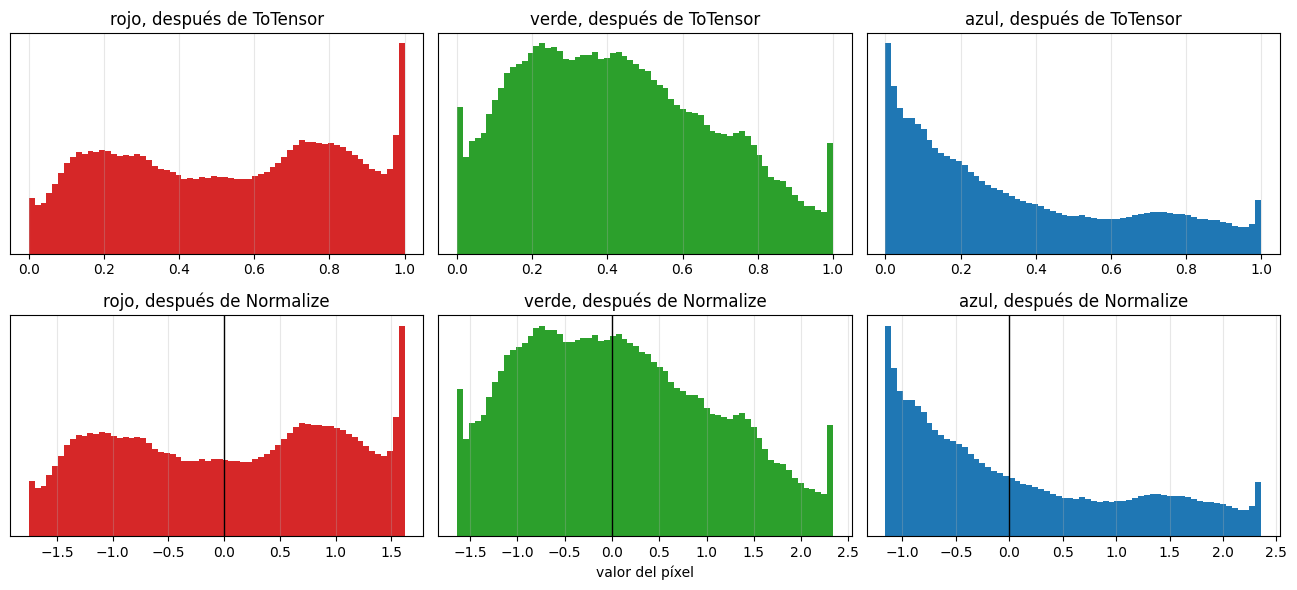

valores posibles después de Normalize:
   rojo   de -1.75 a  1.62
   verde  de -1.64 a  2.34
   azul   de -1.16 a  2.36


In [16]:
pocas = torch.stack([preparar(flores[i][0]) for i in muestra[:100].tolist()])     # [100, 3, 224, 224]
normalizar_flores = transforms.Normalize(media_flores.tolist(), desviacion_flores.tolist())
pocas_normalizadas = normalizar_flores(pocas)

colores = ["tab:red", "tab:green", "tab:blue"]
fig, ejes = plt.subplots(2, 3, figsize=(13, 6))
for canal, nombre in enumerate(["rojo", "verde", "azul"]):
    # 64 cajas: los 256 niveles posibles de un píxel caen de a 4 en cada una
    ejes[0, canal].hist(pocas[:, canal].flatten().numpy(), bins=64, color=colores[canal])
    ejes[0, canal].set_title(f"{nombre}, después de ToTensor")
    ejes[1, canal].hist(pocas_normalizadas[:, canal].flatten().numpy(), bins=64, color=colores[canal])
    ejes[1, canal].axvline(0, color="black", linewidth=1)
    ejes[1, canal].set_title(f"{nombre}, después de Normalize")
for eje in ejes.flat:
    eje.set_yticks([])
    eje.grid(alpha=0.3)
ejes[1, 1].set_xlabel("valor del píxel")
plt.tight_layout()
plt.show()

print("valores posibles después de Normalize:")
for canal, nombre in enumerate(["rojo", "verde", "azul"]):
    print(f"   {nombre:6s} de {(0 - media_flores[canal]) / desviacion_flores[canal]:5.2f} "
          f"a {(1 - media_flores[canal]) / desviacion_flores[canal]:5.2f}")

Los histogramas de abajo tienen exactamente la misma forma que los de arriba; solo cambió el eje. No podría ser de otra manera: `Normalize` resta un número y divide por otro, y una operación así mueve y estira la distribución pero no cambia su forma. El montón de valores bajos del azul sigue en el extremo izquierdo, ahora en −1.16 en vez de 0.

Lo que sí hace `Normalize` es poner los tres canales en la misma escala, centrados en 0 y con desviación 1. Eso es lo que necesita el descenso de gradiente (sección 7 y el módulo 1). Para cambiar la forma del histograma haría falta una transformación no lineal, como la ecualización de histograma (ejercicio 7), que es otra cosa y casi nunca se usa como preprocesamiento de una red.

## 10. El puente: PIL de un lado, tensores del otro

En el video del curso, `ToTensor` es un puente: hay transformaciones que trabajan del lado de las imágenes PIL y otras del lado de los tensores. Probamos varias con los dos tipos de entrada:

In [17]:
foto_pil, _ = flores[0]
foto_tensor = transforms.ToTensor()(foto_pil)

candidatas = [
    ("Resize(256)", transforms.Resize(256)),
    ("CenterCrop(224)", transforms.CenterCrop(224)),
    ("RandomHorizontalFlip()", transforms.RandomHorizontalFlip()),
    ("ColorJitter(brightness=0.2)", transforms.ColorJitter(brightness=0.2)),
    ("Grayscale()", transforms.Grayscale()),
    ("ToTensor()", transforms.ToTensor()),
    ("Normalize(...)", transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])),
    ("ToPILImage()", transforms.ToPILImage()),
]

def probar(transformacion, entrada):
    try:
        transformacion(entrada)
        return "sí"
    except TypeError as error:
        return f"no: {error}"

print(f"{'':30s}{'PIL':6s}tensor")
for nombre, transformacion in candidatas:
    con_pil, con_tensor = probar(transformacion, foto_pil), probar(transformacion, foto_tensor)
    print(f"{nombre:30s}{con_pil if con_pil == 'sí' else 'no':6s}{con_tensor if con_tensor == 'sí' else 'no'}")
    for resultado in (con_pil, con_tensor):
        if resultado != "sí":
            print(f"{'':32s}TypeError: {resultado[4:]}")

                              PIL   tensor
Resize(256)                   sí    sí
CenterCrop(224)               sí    sí
RandomHorizontalFlip()        sí    sí
ColorJitter(brightness=0.2)   sí    sí
Grayscale()                   sí    sí
ToTensor()                    sí    no
                                TypeError: pic should be PIL Image or ndarray. Got <class 'torch.Tensor'>
Normalize(...)                no    sí
                                TypeError: img should be Tensor Image. Got <class 'PIL.Image.Image'>
ToPILImage()                  no    sí
                                TypeError: pic should be Tensor or ndarray. Got <class 'PIL.Image.Image'>.


Las transformaciones de tamaño, recorte, volteo y color funcionan con los dos tipos (el video aclara que hoy `Resize` y `CenterCrop` funcionan en ambos lados). Las que quedan de un solo lado son las de conversión, y `Normalize`, que solo acepta tensores: su documentación dice "This transform does not support PIL Image". Así que `Normalize` siempre va después de `ToTensor`.

Que una transformación acepte tensores no quiere decir que pueda ir en cualquier lugar. Las de color, como `ColorJitter`, suponen que un tensor de punto flotante tiene valores entre 0 y 1 (la guía de torchvision lo dice para todas: "Tensor images with a float dtype are expected to have values in [0, 1]", en [*Dtype and expected value range*](https://docs.pytorch.org/vision/stable/transforms.html#dtype-and-expected-value-range)). Si se ponen después de `Normalize`, no dan error:

In [18]:
normalizada = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])(foto_tensor)
torch.manual_seed(0)
con_brillo = transforms.ColorJitter(brightness=0.2)(normalizada)
print(f"normalizada            : valores de {normalizada.min():.2f} a {normalizada.max():.2f}, "
      f"negativos {(normalizada < 0).float().mean():.0%}")
print(f"ColorJitter después    : valores de {con_brillo.min():.2f} a {con_brillo.max():.2f}, "
      f"negativos {(con_brillo < 0).float().mean():.0%}")

normalizada            : valores de -2.12 a 2.64, negativos 57%
ColorJitter después    : valores de 0.00 a 1.00, negativos 0%


`ColorJitter` recortó el resultado a [0, 1]: los valores negativos, más de la mitad de la foto, quedaron en 0, y los que pasaban de 1 quedaron en 1. Se perdió información sin ningún aviso. Por eso el orden habitual es: transformaciones de tamaño y de color primero, `ToTensor` después y `Normalize` al final.

Que `Resize` funcione en los dos lados no significa que dé lo mismo. Achicamos la misma foto con PIL y como tensor `uint8`, con y sin *antialiasing* (el suavizado que evita que los detalles finos se conviertan en patrones falsos al achicar):

In [19]:
foto_uint8 = transforms.PILToTensor()(foto_pil)                       # tensor uint8 de 0 a 255
con_pil = torch.from_numpy(np.array(transforms.Resize(256)(foto_pil))).permute(2, 0, 1).int()

for antialias in [True, False]:
    con_tensor = transforms.Resize(256, antialias=antialias)(foto_uint8).int()
    diferencia = (con_tensor - con_pil).abs()                         # en niveles de 0 a 255
    print(f"tensor con antialias={antialias!s:5s}: diferencia con PIL media {diferencia.float().mean():.2f}, "
          f"máxima {diferencia.max()}, valores que difieren en más de 2: {(diferencia > 2).float().mean():.1%}")

tensor con antialias=True : diferencia con PIL media 0.14, máxima 1, valores que difieren en más de 2: 0.0%
tensor con antialias=False: diferencia con PIL media 1.98, máxima 62, valores que difieren en más de 2: 21.6%


Con `antialias=True`, que es el valor por defecto, el tensor y PIL difieren a lo más en 1 nivel de 255: son la misma imagen. Sin *antialiasing*, la diferencia llega a 62 niveles y uno de cada cinco valores se aleja en más de 2. La documentación de `Resize` explica por qué: en PIL el suavizado "is always applied on bilinear or bicubic modes", y en tensores se aplica solo con `antialias=True`, que es el valor por defecto desde la versión 0.17 de torchvision ("The default value changed from None to True in v0.17, for the PIL and Tensor backends to be consistent"). Con versiones anteriores, el mismo código daba resultados distintos según el tipo de la entrada.

Al pasar de 500 a 256 píxeles, la foto se achica unas dos veces, y a simple vista las tres versiones se parecen. El efecto se nota cuando se achica más. Con `Resize(64)`, el tamaño que usaría un modelo pequeño, cada píxel nuevo resume unos ocho originales por lado:

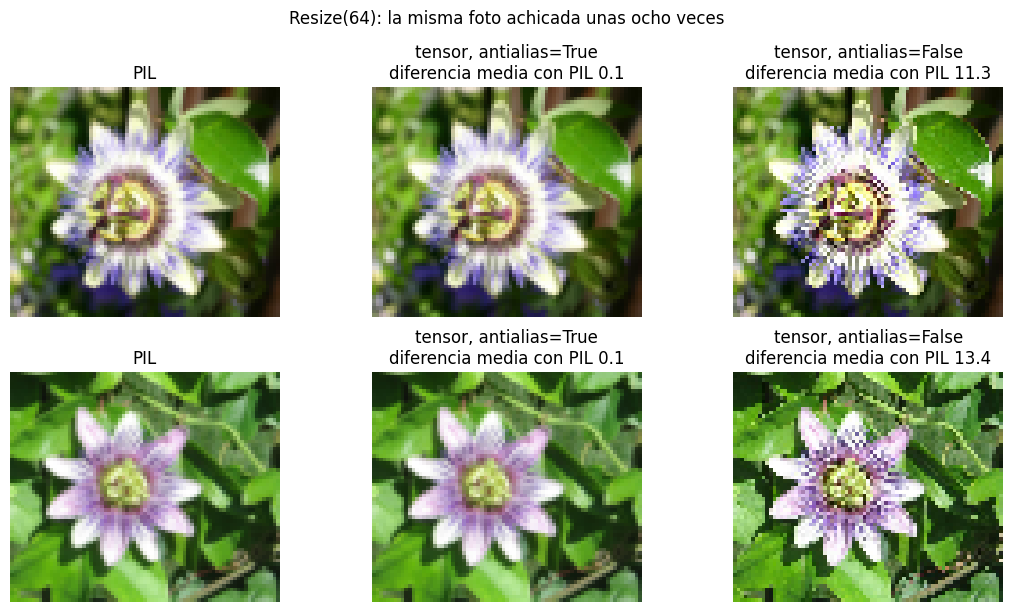

In [20]:
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.2))
for fila, indice in enumerate([0, 100]):
    foto, _ = flores[indice]
    foto_entera = transforms.PILToTensor()(foto)
    chicas = {
        "PIL": torch.from_numpy(np.array(transforms.Resize(64)(foto))).permute(2, 0, 1).int(),
        "tensor, antialias=True": transforms.Resize(64, antialias=True)(foto_entera).int(),
        "tensor, antialias=False": transforms.Resize(64, antialias=False)(foto_entera).int(),
    }
    for columna, (nombre, chica) in enumerate(chicas.items()):
        diferencia = (chica - chicas["PIL"]).abs().float().mean()
        ejes[fila, columna].imshow(chica.permute(1, 2, 0).numpy().astype(np.uint8), interpolation="nearest")
        ejes[fila, columna].set_title(nombre if nombre == "PIL" else f"{nombre}\ndiferencia media con PIL {diferencia:.1f}")
        ejes[fila, columna].axis("off")
plt.suptitle("Resize(64): la misma foto achicada unas ocho veces")
plt.tight_layout()
plt.show()

Las dos primeras columnas son la misma imagen. La tercera tiene bordes dentados y puntos de colores que no estaban en la foto, sobre todo en los filamentos finos de las pasionarias: sin suavizar, cada píxel nuevo toma el color de unos pocos píxeles originales e ignora a sus vecinos, y los detalles más finos que la nueva grilla se convierten en patrones falsos.

## 11. `transforms.v2`

Todo lo anterior usa `torchvision.transforms`, la API original. Desde la versión 0.15 hay una nueva, `torchvision.transforms.v2`, y la guía de torchvision es directa: "We recommend using the torchvision.transforms.v2 transforms instead of those in torchvision.transforms. They’re faster and they can do more things" ([*V1 or V2? Which one should I use?*](https://docs.pytorch.org/vision/stable/transforms.html#v1-or-v2-which-one-should-i-use)). Para clasificar imágenes casi todo se escribe igual. La diferencia principal está en el puente: en v2, `ToTensor` está obsoleto.

In [21]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    v2.ToTensor()(foto_pil)
for aviso in avisos:
    print(f"{aviso.category.__name__}: {aviso.message}")

El reemplazo son dos pasos que separan las dos tareas de `ToTensor`: `v2.ToImage()` convierte a tensor sin cambiar los valores, y `v2.ToDtype(torch.float32, scale=True)` cambia el tipo y escala de 0-255 a 0-1 ([*Conversion*](https://docs.pytorch.org/vision/stable/transforms.html#conversion)). Comprobamos que dan lo mismo que `ToTensor`:

In [22]:
puente_v2 = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
con_v2 = puente_v2(foto_pil)

print("tipo        :", type(con_v2).__name__, "(una subclase de torch.Tensor)")
print("forma, dtype:", tuple(con_v2.shape), con_v2.dtype)
print("¿Idéntico a ToTensor?        ", torch.equal(con_v2.as_subclass(torch.Tensor), foto_tensor))
print("¿Igual salvo redondeo?       ", torch.allclose(con_v2, foto_tensor))
print(f"diferencia máxima            : {(con_v2 - foto_tensor).abs().max():.1e}")

tipo        : Image (una subclase de torch.Tensor)
forma, dtype: (3, 500, 591) torch.float32
¿Idéntico a ToTensor?         False
¿Igual salvo redondeo?        True
diferencia máxima            : 6.0e-08


No son idénticos bit a bit, pero la diferencia más grande es $6 \times 10^{-8}$, el último dígito de un `float32`: dividir por 255 y multiplicar por $1/255$ no redondean igual. Es lo que anuncia el aviso: "Output is equivalent up to float precision". El resultado es un `tv_tensors.Image`, un tensor con una etiqueta que le dice a las transformaciones v2 que es una imagen.

Separar los dos pasos deja a la vista una opción que `ToTensor` escondía (en v1 también existía, con `PILToTensor`, como en la sección 7): convertir a tensor `uint8` al principio y achicar sobre enteros, que es lo que recomienda la guía para el mejor rendimiento ("Use tensors instead of PIL images", "Use torch.uint8 dtype, especially for resizing", en [*Performance considerations*](https://docs.pytorch.org/vision/stable/transforms.html#performance-considerations)). `Normalize`, en cambio, sigue pidiendo un tensor de punto flotante:

In [23]:
for nombre, entrada in [("PIL", foto_pil), ("tensor uint8", v2.ToImage()(foto_pil))]:
    try:
        v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])(entrada)
    except TypeError as error:
        print(f"v2.Normalize con {nombre:12s} -> TypeError: {error}")

pipeline_v1 = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                                  transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
pipeline_v2 = v2.Compose([v2.ToImage(), v2.Resize(256), v2.CenterCrop(224), v2.ToDtype(torch.float32, scale=True),
                          v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

a, b = pipeline_v1(foto_pil), pipeline_v2(foto_pil)
print(f"\nv1 contra v2: forma {tuple(a.shape)} y {tuple(b.shape)}, "
      f"diferencia media {(a - b).abs().mean():.1e}, máxima {(a - b).abs().max():.3f}")

v2.Normalize con PIL          -> TypeError: Normalize() does not support PIL images.
v2.Normalize con tensor uint8 -> TypeError: Input tensor should be a float tensor. Got torch.uint8.

v1 contra v2: forma (3, 224, 224) y (3, 224, 224), diferencia media 3.6e-05, máxima 0.018


El pipeline v2 achica sobre el tensor `uint8` y el v1 sobre la imagen PIL, y aun así la diferencia media es del orden de $10^{-5}$. La máxima, 0.018, es exactamente un nivel de 255 después de normalizar: $1/255/0.224 \approx 0.018$. Unos pocos valores redondearon a un entero vecino, que es lo que advierte la guía ("there might be negligible differences due to implementation differences").

En el resto de este notebook seguimos con la API v1, la del curso. Pasar a v2 es, según la misma guía, cambiar el import: "These transforms are fully backward compatible with the v1 ones, so if you’re already using tranforms from torchvision.transforms, all you need to do to is to update the import to torchvision.transforms.v2" (así, con sus erratas).

## 12. Depurar paso a paso

El consejo del video para cuando un pipeline hace algo raro: sacar una sola imagen y aplicarle las transformaciones de a una, mirando qué cambia en cada paso. Esta función lo hace, y para cada etapa imprime el tipo, la forma y el rango, y dibuja la imagen:

original     PIL     tamaño (ancho, alto) (591, 500)   modo RGB
Resize       PIL     tamaño (ancho, alto) (302, 256)   modo RGB
CenterCrop   PIL     tamaño (ancho, alto) (224, 224)   modo RGB
ToTensor     tensor  forma (3, 224, 224)   torch.float32   valores de 0.000 a 1.000
Normalize    tensor  forma (3, 224, 224)   torch.float32   valores de -2.101 a 2.640


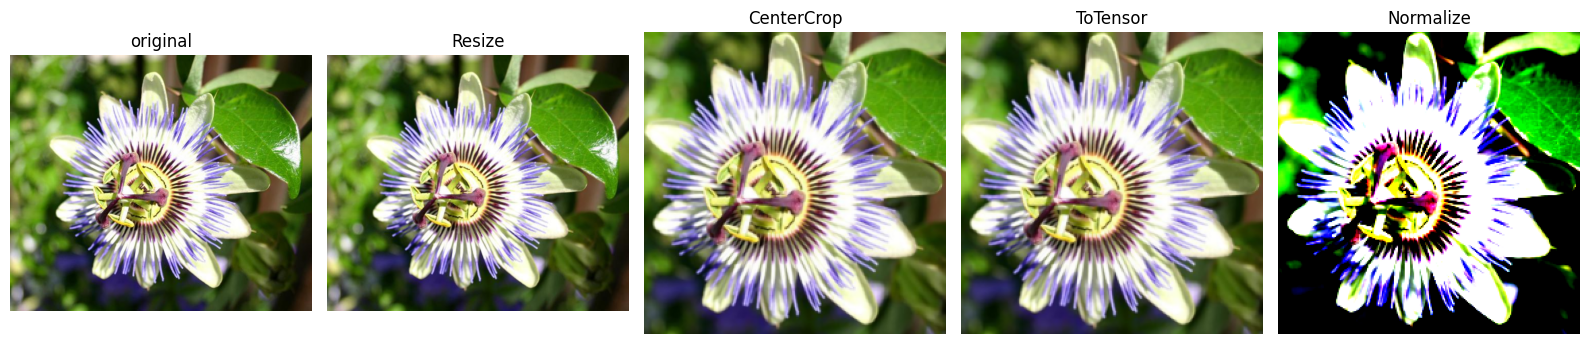

In [24]:
def paso_a_paso(imagen, pasos):
    etapas = [("original", imagen)]
    for nombre, transformacion in pasos:
        etapas.append((nombre, transformacion(etapas[-1][1])))

    fig, ejes = plt.subplots(1, len(etapas), figsize=(3.2 * len(etapas), 3.4))
    for eje, (nombre, x) in zip(ejes, etapas):
        if isinstance(x, Image.Image):
            print(f"{nombre:12s} PIL     tamaño (ancho, alto) {x.size}   modo {x.mode}")
            eje.imshow(x)
        else:
            print(f"{nombre:12s} tensor  forma {tuple(x.shape)}   {x.dtype}   valores de {x.min():.3f} a {x.max():.3f}")
            eje.imshow(x.permute(1, 2, 0).clamp(0, 1).numpy())     # imshow necesita [alto, ancho, canales] entre 0 y 1
        eje.set_title(nombre)
        eje.axis("off")
    plt.tight_layout()
    plt.show()
    return etapas[-1][1]


normalizar_imagenet = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
final = paso_a_paso(foto_pil, [("Resize", achicar), ("CenterCrop", recortar),
                               ("ToTensor", transforms.ToTensor()), ("Normalize", normalizar_imagenet)])

Cada línea dice qué cambió. `Resize` y `CenterCrop` trabajan sobre la imagen PIL y solo cambian el tamaño; `ToTensor` cruza el puente (de `(224, 224)` en orden ancho-alto a `[3, 224, 224]`) y deja los valores entre 0 y 1; `Normalize` los lleva a un rango de −2.1 a 2.6.

La última imagen se ve rara, y no es un error del pipeline. `imshow` espera valores entre 0 y 1, así que todo lo negativo quedó negro y todo lo mayor que 1, saturado. Para mirar una imagen normalizada hay que deshacer la normalización: multiplicar por la desviación y sumar la media. Es lo mismo que haremos al revisar el aumento de datos en `03-robustez/01_pipelines_a_prueba_de_fallas`.

desnormalizada: valores de 0.000 a 1.000
¿Igual a la salida de ToTensor? True


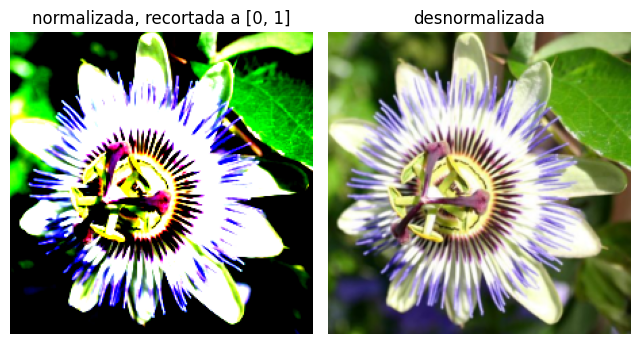

In [25]:
def desnormalizar(x, media=(0.485, 0.456, 0.406), desviacion=(0.229, 0.224, 0.225)):
    return x * torch.tensor(desviacion).view(3, 1, 1) + torch.tensor(media).view(3, 1, 1)


recuperada = desnormalizar(final)
print(f"desnormalizada: valores de {recuperada.min():.3f} a {recuperada.max():.3f}")
print("¿Igual a la salida de ToTensor?", torch.allclose(recuperada, recortar(transforms.ToTensor()(achicar(foto_pil))), atol=1e-6))

fig, ejes = plt.subplots(1, 2, figsize=(6.5, 3.4))
ejes[0].imshow(final.permute(1, 2, 0).clamp(0, 1).numpy())
ejes[0].set_title("normalizada, recortada a [0, 1]")
ejes[1].imshow(recuperada.permute(1, 2, 0).clamp(0, 1).numpy())
ejes[1].set_title("desnormalizada")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

## 13. El pipeline completo

Antes de armarlo, un tropiezo que menciona el curso y que pasa más de lo que uno creería: guardar el pipeline en una variable llamada `transforms`. El nombre tapa al módulo, y la siguiente vez que se quiere usar una transformación, ya no está:

In [26]:
transforms = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])   # el nombre tapa al módulo
try:
    otra = transforms.Compose([transforms.ToTensor()])
except AttributeError as error:
    print("AttributeError:", error)

from torchvision import transforms                                                    # lo recuperamos
print("transforms vuelve a ser:", transforms.__name__)

AttributeError: 'Compose' object has no attribute 'Compose'
transforms vuelve a ser: torchvision.transforms


El error no dice nada de nombres: dice que un objeto `Compose` no tiene el atributo `Compose`. Para no caer, el pipeline se guarda con otro nombre, como `transformacion` o `pipeline`.

Ahora sí, todo junto. Usamos la media y la desviación de las flores, porque este pipeline es para entrenar desde cero; con un modelo preentrenado irían las de ImageNet:

In [27]:
MEDIA_FLORES = [round(v, 3) for v in media_flores.tolist()]
DESV_FLORES = [round(v, 3) for v in desviacion_flores.tolist()]
print("media:", MEDIA_FLORES, "  desviación:", DESV_FLORES)

transformacion = transforms.Compose([
    transforms.Resize(256),            # lado corto a 256, sin deformar
    transforms.CenterCrop(224),        # cuadrado de 224 × 224 del centro
    transforms.ToTensor(),             # PIL -> tensor [3, 224, 224] entre 0 y 1
    transforms.Normalize(MEDIA_FLORES, DESV_FLORES),
])

flores_listas = Flores(CARPETA, transform=transformacion)
cargador = DataLoader(flores_listas, batch_size=4, shuffle=True, generator=torch.Generator().manual_seed(0))
imagenes, etiquetas = next(iter(cargador))

print("imágenes:", tuple(imagenes.shape), imagenes.dtype)
print("etiquetas:", etiquetas.tolist(), etiquetas.dtype)
print("media por canal del lote      :", imagenes.mean(dim=(0, 2, 3)).numpy().round(2))
print("desviación por canal del lote :", imagenes.std(dim=(0, 2, 3)).numpy().round(2))

media: [0.52, 0.412, 0.33]   desviación: [0.297, 0.252, 0.284]
imágenes: (4, 3, 224, 224) torch.float32
etiquetas: [47, 4, 19, 42] torch.int64
media por canal del lote      : [ 0.01  0.4  -0.31]
desviación por canal del lote : [1.2  1.16 0.84]


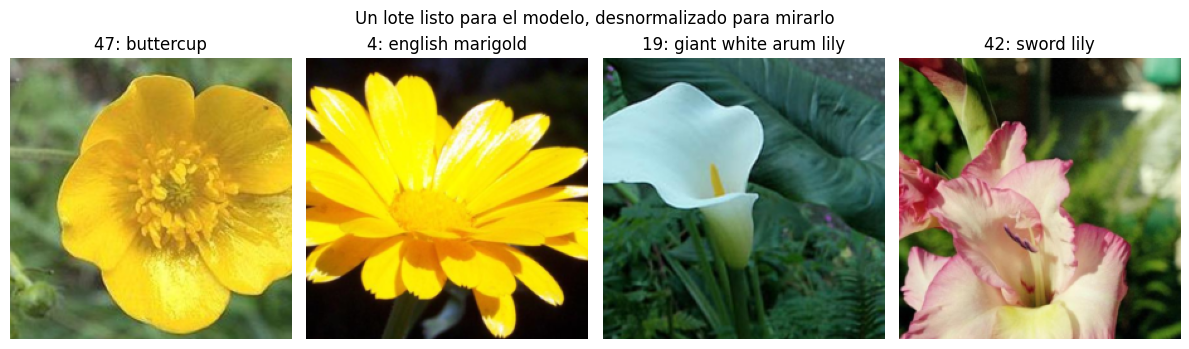

In [28]:
fig, ejes = plt.subplots(1, 4, figsize=(12, 3.6))
for eje, imagen, etiqueta in zip(ejes, imagenes, etiquetas):
    eje.imshow(desnormalizar(imagen, MEDIA_FLORES, DESV_FLORES).permute(1, 2, 0).clamp(0, 1).numpy())
    eje.set_title(f"{etiqueta.item()}: {nombres[etiqueta]}")
    eje.axis("off")
plt.suptitle("Un lote listo para el modelo, desnormalizado para mirarlo")
plt.tight_layout()
plt.show()

El lote tiene la forma que el modelo espera, `[4, 3, 224, 224]`, y las etiquetas son enteros `int64` entre 0 y 101, lo que pide `CrossEntropyLoss`. La media y la desviación del lote no son exactamente 0 y 1: son 4 fotos, y cada una tiene sus propios colores.

Este lote resuelve el acceso y la calidad. Falta la tercera parte del pipeline, la **eficiencia**: dividir en entrenamiento, validación y prueba y cargar por lotes sin trampas, que es el tema de `02-carga/01_division_y_dataloader`.

## 14. Resumen

- Un `DataLoader` apila las muestras con `torch.stack`: necesita **tensores** y **del mismo tamaño**. Con imágenes PIL falla `default_collate`; con tensores de tamaños distintos falla `torch.stack`.
- Oxford Flowers tiene 856 tamaños distintos. Casi todas las fotos tienen el lado corto de 500 píxeles, y las proporciones más comunes son 4:3 y 3:2.
- `Resize((h, w))` fuerza el tamaño y **deforma**: en la mitad de las fotos, el lado largo se comprime 1.33 veces más que el corto o peor. `Resize(n)` lleva el lado corto a `n` y mantiene la proporción; después, `CenterCrop` recorta el centro y bota los bordes (en la foto mediana, conserva el 57%). 256 y 224 son los valores de muchos modelos entrenados con ImageNet, como ResNet-50 con los pesos V1.
- `ToTensor` hace tres cosas: convierte a tensor, pasa de `[alto, ancho, canales]` a `[canales, alto, ancho]` y divide por 255. PIL da los tamaños como `(ancho, alto)`.
- Escalar importa desde el primer paso: con píxeles de 0 a 255, una capa recién creada da respuestas con 96% de confianza, una pérdida de 196 en vez de 4.6 y gradientes cientos de veces más grandes.
- La media y la desviación de ImageNet se calcularon con una muestra perdida de ImageNet, y su desviación es el promedio de las desviaciones por imagen, no la de todos los píxeles. Se usan con modelos preentrenados en ImageNet; para entrenar desde cero se miden en el propio entrenamiento.
- `Normalize` centra y escala cada canal, pero no cambia la forma de la distribución.
- Las transformaciones de tamaño, recorte y color aceptan PIL y tensores; `Normalize` solo tensores de punto flotante. En tensores, `Resize` da lo mismo que en PIL gracias al `antialias=True` por defecto.
- `transforms.v2` es la API recomendada. Su `ToTensor` está obsoleto y se reemplaza por `ToImage` y `ToDtype(torch.float32, scale=True)`.
- Para depurar, aplicar las transformaciones de a una y mirar tipo, forma, rango e imagen en cada paso. Para mirar una imagen normalizada, primero desnormalizarla.

## Ejercicios

1. Antes de ejecutar nada: ¿qué tamaño deja `Resize(256)` en la foto más alta del dataset (índice 7322)? ¿Qué fracción de ella conserva `CenterCrop(224)`? Compruébalo.
2. Compara `Resize(224)` + `CenterCrop(224)` con `Resize(256)` + `CenterCrop(224)`. ¿Cuánto de la foto mediana conserva cada uno? ¿Qué se gana y qué se pierde con el margen de 256?
3. Escribe un `collate_fn` que devuelva las imágenes en una lista en vez de apilarlas, y pásaselo al `DataLoader` de la sección 4. ¿Deja de fallar? ¿Qué problema aparecería al pasarle ese lote a un modelo?
4. Calcula la media y la desviación de las flores con 50, 200 y 1.000 fotos de la muestra. ¿Desde cuántas fotos se estabilizan en el segundo decimal?
5. Repite el cálculo de la sección 8 con `Resize((224, 224))` en vez de `Resize(256)` + `CenterCrop(224)`. ¿Cambia la media? ¿Hacia dónde, y por qué crees que pasa?
6. Arma el pipeline de la sección 13 con `transforms.v2` y compara los dos lotes. ¿Qué `atol` necesita `torch.allclose` para darlos por iguales? Después de `Normalize`, ¿a cuántos niveles de 0 a 255 corresponde esa diferencia en cada canal?
7. `transforms.functional.equalize` ecualiza el histograma de una imagen (necesita una imagen PIL o un tensor `uint8`). Aplícala a la foto de la sección 12 y compara su histograma con el original. A diferencia de `Normalize`, ¿cambia la forma?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026. La documentación de torchvision corresponde a la versión estable de esa fecha (0.29) y la de PyTorch a la 2.14; el notebook se ejecutó con las versiones que imprime la sección 1, y todas las conductas citadas se comprobaron en el código.

**Del material del curso**

- **Oxford Flowers 102**, [página del Visual Geometry Group](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) (Nilsback y Zisserman), sección *Overview*: "Each class consists of between 40 and 258 images" y "The images have large scale, pose and light variations".
- El video *Transform Pipelines* del curso, para el planteamiento: las imágenes de tamaños distintos que no se pueden apilar, `Resize` con dos valores que deforma, las tres cosas de `ToTensor`, las dos razones para escalar, la afirmación sobre los valores amontonados cerca de 0 o de 1 (que la sección 9 revisa), el puente de `ToTensor`, el consejo de depurar paso a paso y el de no llamar `transforms` a una variable.

**Documentación de torchvision**

- [`transforms.Resize`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Resize.html), parámetro `size`: "If size is a sequence like (h, w), output size will be matched to this. If size is an int, smaller edge of the image will be matched to this number. i.e, if height > width, then image will be rescaled to (size * height / width, size)." Parámetro `antialias`: "on PIL images, antialiasing is always applied on bilinear or bicubic modes", "True (default): will apply antialiasing for bilinear or bicubic modes" y "The default value changed from None to True in v0.17, for the PIL and Tensor backends to be consistent."
- [`transforms.CenterCrop`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.CenterCrop.html): "Crops the given image at the center." y "If size is an int instead of sequence like (h, w), a square crop (size, size) is made."
- [`transforms.ToTensor`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html): "Converts a PIL Image or numpy.ndarray (H x W x C) in the range [0, 255] to a torch.FloatTensor of shape (C x H x W) in the range [0.0, 1.0] if the PIL Image belongs to one of the modes (L, LA, P, I, F, RGB, YCbCr, RGBA, CMYK, 1) or if the numpy.ndarray has dtype = np.uint8" y "In the other cases, tensors are returned without scaling."
- [`transforms.Normalize`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Normalize.html): "Normalize a tensor image with mean and standard deviation. This transform does not support PIL Image." y la fórmula "output[channel] = (input[channel] - mean[channel]) / std[channel]".
- [*Transforming images, videos, boxes and more*](https://docs.pytorch.org/vision/stable/transforms.html), la guía de transforms. Sección *V1 or V2? Which one should I use?*: "We recommend using the torchvision.transforms.v2 transforms instead of those in torchvision.transforms. They’re faster and they can do more things", "In Torchvision 0.15 (March 2023), we released a new set of transforms available in the torchvision.transforms.v2 namespace", "These transforms are fully backward compatible with the v1 ones, so if you’re already using tranforms from torchvision.transforms, all you need to do to is to update the import to torchvision.transforms.v2" y "In terms of output, there might be negligible differences due to implementation differences." Sección *Dtype and expected value range*: "Tensor images with a float dtype are expected to have values in [0, 1]". Sección *Performance considerations*: "Use tensors instead of PIL images" y "Use torch.uint8 dtype, especially for resizing". Sección *Conversion*: "v2.ToImage () Convert a tensor, ndarray, or PIL Image to Image ; this does not scale values", "v2.ToDtype (dtype[, scale]) Converts the input to a specific dtype, optionally scaling the values for images or videos" y, bajo *Deprecated*, "v2.ToTensor () [DEPRECATED] Use v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]) instead."
- [`ResNet50_Weights`](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html#torchvision.models.ResNet50_Weights), pesos `IMAGENET1K_V1`: "The images are resized to resize_size=[256] using interpolation=InterpolationMode.BILINEAR, followed by a central crop of crop_size=[224]. Finally the values are first rescaled to [0.0, 1.0] and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]."
- [*Models and pre-trained weights*](https://docs.pytorch.org/vision/stable/models.html#using-the-pre-trained-models), sección *Using the pre-trained models*: "There is no standard way to do this as it depends on how a given model was trained" y "Using the correct preprocessing method is critical and failing to do so may lead to decreased accuracy or incorrect outputs."
- [Issue #1439 de torchvision](https://github.com/pytorch/vision/issues/1439), *Origin of the means and stds used for preprocessing?* (2019). En el cuerpo del issue, la tabla del autor, cuya fila "train set only, resize to 256 and center crop to 224" da desviaciones de `[0.2724, 0.2637, 0.2761]`, y su actualización: "The process for obtaining the values of `mean` and `std` was roughly equivalent to the following but the the concrete `subset` that was used is lost". Comentario de nizhib del 10 de octubre, que cita el archivo `datasets/imagenet.lua` de `fb.resnet.torch`: "Computed from random subset of ImageNet training images". Comentario de colesbury del 21 de octubre: "I probably just used the mean / std from the previous Lua ImageNet training script", con un link a `donkey.lua` de `soumith/imagenet-multiGPU.torch`, y sobre ese script: "It uses the average standard deviation of an individual image's channel instead of the an estimate of the standard deviation across the entire dataset"; en el mismo comentario, "the exact choice does not matter as long as they approximately whiten the input".

**Documentación de PyTorch y de Pillow**

- [*Working with collate_fn*](https://docs.pytorch.org/docs/stable/data.html#working-with-collate-fn), en `torch.utils.data`: "When automatic batching is enabled, collate_fn is called with a list of data samples at each time", "It always prepends a new dimension as the batch dimension" y que un `collate_fn` propio sirve para "padding sequences of various lengths".
- [`default_collate`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.default_collate): la tabla de tipos de entrada, que incluye "torch.Tensor -> torch.Tensor (with an added outer dimension batch size)", arreglos de NumPy, números, textos, diccionarios y secuencias, y no incluye imágenes PIL.
- [`PIL.Image.open`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open): "This is a lazy operation; this function identifies the file, but the file remains open and the actual image data is not read from the file until you try to process the data". [`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert): "Returns a converted copy of this image." [`Image.size`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.size): "The size is given as a 2-tuple (width, height)."

**Lo que no viene de una fuente** son los números de este notebook (tamaños, deformación, fracción conservada, la capa recién creada, las estadísticas de las flores, los histogramas y las diferencias entre PIL, tensores y v2): todos salen de las celdas de código. También es nuestra la comprobación de que la varianza de todos los píxeles es la suma de la varianza dentro de cada foto y la varianza entre fotos, que explica por qué la desviación de ImageNet es más chica.